In [ ]:
#imports
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.utils import class_weight
import seaborn as sns
from google.colab import drive
from tensorflow.keras.applications import VGG16

# Configurações de Hiperparâmetros
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10 #Podemos ajustar isso conforme o comportamento do treino

In [ ]:
#Carregar e dividr os dados em (80% treino / 20% validação)

drive.mount('/content/drive')

#Caminho da pasta
DATASET_PATH = '/content/drive/MyDrive/dataset/'

#Pipeline de Pré-processamento e Divisão (80/20)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=False,
)

# Gerador de Treino
train_generator = train_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary', # Legítima ou Fraudulenta
    subset='training',
    shuffle=True
)

#Gerador de Validação/Teste
validation_generator = train_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    shuffle=False # Manter False para não bagunçar a Matriz de Confusão depois
)

Mounted at /content/drive
Found 880 images belonging to 2 classes.
Found 220 images belonging to 2 classes.


In [ ]:
#construção da Arquitetura (Transfer Learning)

# 1. Carrega a VGG16 original
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# 2. Ativa a capacidade de treino do modelo base
base_model.trainable = True

# 3. Congela os blocos 1, 2, 3, e 4. Libera Apenas o Bloco 5.
# A VGG16 tem 19 camadas no total. Vamos congelar até a camada 'block5_conv1'
for layer in base_model.layers[:-4]:
    layer.trainable = False

# 3. Monta a cabeça de classificação com Dropout para controle
model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

# 5. CRÍTICO: Learning rate extremamente baixo para Fine-Tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001), # 1e-5
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,137,729 (80.63 MB)

 Trainable params: 13,502,465 (51.51 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [ ]:
# ==========================================
# 1. EXECUÇÃO DO TREINAMENTO (15 ÉPOCAS)
# ==========================================
print("Iniciando o treinamento com Fine-Tuning do Bloco 5 da VGG16...")

history = model.fit(
    train_generator,
    epochs=15,
    validation_data=validation_generator
)

print("\nTreinamento concluído com sucesso!")
print("="*50)

Iniciando o treinamento com Fine-Tuning do Bloco 5 da VGG16...
Epoch 1/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 837s 29s/step - accuracy: 0.5739 - loss: 0.7059 - precision: 0.5744 - recall: 0.5705 - val_accuracy: 0.6864 - val_loss: 0.6216 - val_precision: 0.7412 - val_recall: 0.5727
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 781s 28s/step - accuracy: 0.6568 - loss: 0.6308 - precision: 0.6620 - recall: 0.6409 - val_accuracy: 0.6955 - val_loss: 0.6079 - val_precision: 0.7087 - val_recall: 0.6636
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 780s 28s/step - accuracy: 0.6898 - loss: 0.5895 - precision: 0.7052 - recall: 0.6523 - val_accuracy: 0.6727 - val_loss: 0.5934 - val_precision: 0.7436 - val_recall: 0.5273
Epoch 4/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 812s 29s/step - accuracy: 0.7273 - loss: 0.5379 - precision: 0.7632 - recall: 0.6591 - val_accuracy: 0.6818 - val_loss: 0.6072 - val_precision: 0.8125 - val_recall: 0.4727
Epoch 5/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 804s 29s/step - accuracy: 0.7250 - loss: 0.5216 - precision

In [ ]:
#para carregar o modelo treinado e salvo anteriormente!
# Carrega o modelo com todos os pesos treinados instantaneamente
model = tf.keras.models.load_model('modelo_tcc_vgg16_final.keras')
print("Modelo carregado com sucesso! Pronto para uso.")

Modelo carregado com sucesso! Pronto para uso.


7/7 ━━━━━━━━━━━━━━━━━━━━ 132s 19s/step

============================== RELATÓRIO DE CLASSIFICAÇÃO ==============================
                precision    recall  f1-score   support

   fraudulenta       0.67      0.82      0.74       110
genuine_site_0       0.77      0.60      0.67       110

      accuracy                           0.71       220
     macro avg       0.72      0.71      0.71       220
  weighted avg       0.72      0.71      0.71       220

----------------------------------------------------------------------------------------



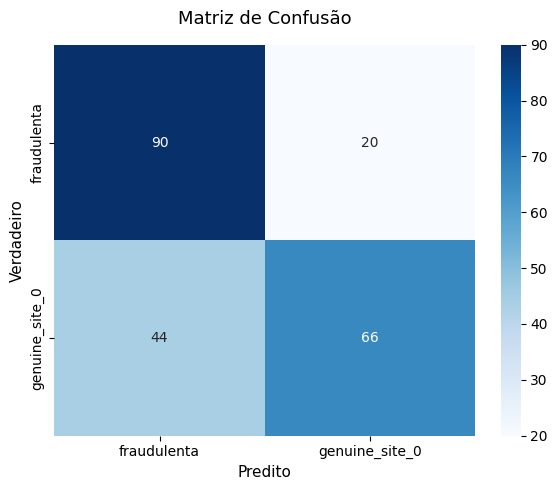


----------------------------------------------------------------------------------------



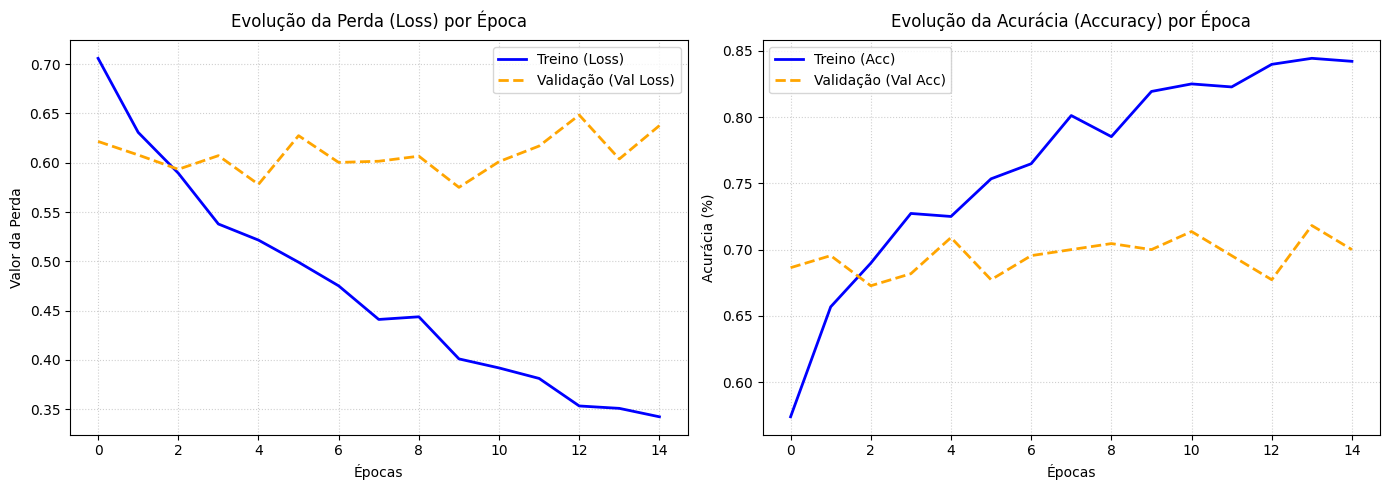


----------------------------------------------------------------------------------------



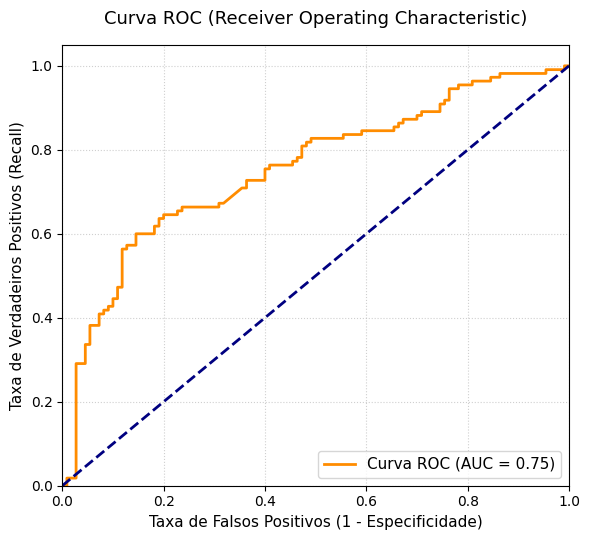


----------------------------------------------------------------------------------------



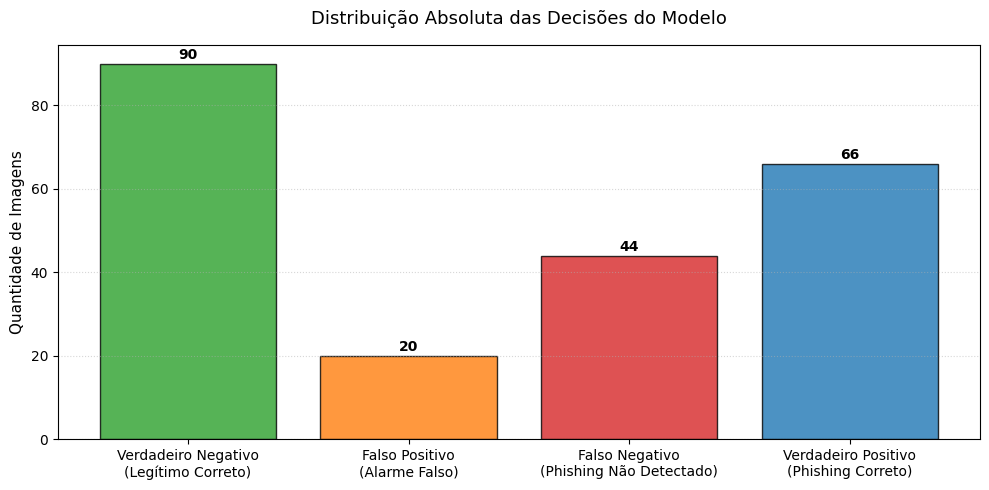

In [ ]:
# ==============================================================================
# PIPELINE DE AVALIAÇÃO VISUAL INDEPENDENTE
# ==============================================================================

# 1. Gerar as predições do conjunto de validação
validation_generator.reset()
predictions = model.predict(validation_generator)

y_pred = (predictions >= 0.5).astype(int).flatten()
y_true = validation_generator.classes
class_labels = list(validation_generator.class_indices.keys())

# --- RELATÓRIO TEXTUAL ---
print("\n" + "="*30 + " RELATÓRIO DE CLASSIFICAÇÃO " + "="*30)
print(classification_report(y_true, y_pred, target_names=class_labels))
print("-" * 88 + "\n")


# --- GRÁFICO 1: MATRIZ DE CONFUSÃO ---
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Matriz de Confusão', fontsize=13, pad=15)
plt.ylabel('Verdadeiro', fontsize=11)
plt.xlabel('Predito', fontsize=11)
plt.tight_layout()
plt.show()  # Força a renderização isolada e fecha a figura atual

print("\n" + "-" * 88 + "\n")


# --- GRÁFICO 2: CURVAS DE APRENDIZADO (LOSS E ACCURACY) ---
# Criar uma figura com dois subgráficos lado a lado, mas isolada dos demais
plt.figure(figsize=(14, 5))

# Subgráfico A: Perda (Loss)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Treino (Loss)', color='blue', linewidth=2)
plt.plot(history.history['val_loss'], label='Validação (Val Loss)', color='orange', linewidth=2, linestyle='--')
plt.title('Evolução da Perda (Loss) por Época', fontsize=12, pad=10)
plt.xlabel('Épocas', fontsize=10)
plt.ylabel('Valor da Perda', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)

# Subgráfico B: Acurácia (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Treino (Acc)', color='blue', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validação (Val Acc)', color='orange', linewidth=2, linestyle='--')
plt.title('Evolução da Acurácia (Accuracy) por Época', fontsize=12, pad=10)
plt.xlabel('Épocas', fontsize=10)
plt.ylabel('Acurácia (%)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()  # Força a renderização isolada e fecha a figura atual

print("\n" + "-" * 88 + "\n")


# --- GRÁFICO 3: CURVA ROC ---
from sklearn.metrics import roc_curve, auc

probabilidades = predictions.flatten()
fpr, tpr, thresholds = roc_curve(y_true, probabilidades)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5.5))  # Ajustado para manter proporção parecida com a matriz
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=11)
plt.ylabel('Taxa de Verdadeiros Positivos (Recall)', fontsize=11)
plt.title('Curva ROC (Receiver Operating Characteristic)', fontsize=13, pad=15)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()  # Força a renderização isolada e fecha a figura atual

print("\n" + "-" * 88 + "\n")


# --- GRÁFICO 4: DISTRIBUIÇÃO ABSOLUTA DE DECISÕES ---
tn, fp, fn, tp = cm.ravel()

categorias = [
    'Verdadeiro Negativo\n(Legítimo Correto)',
    'Falso Positivo\n(Alarme Falso)',
    'Falso Negativo\n(Phishing Não Detectado)',
    'Verdadeiro Positivo\n(Phishing Correto)'
]
valores = [tn, fp, fn, tp]
cores = ['#2ca02c', '#ff7f0e', '#d62728', '#1f77b4']

plt.figure(figsize=(10, 5))
bars = plt.bar(categorias, valores, color=cores, edgecolor='black', alpha=0.8)

# Adiciona os valores numéricos em cima de cada barra
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, int(yval), ha='center', va='bottom', fontweight='bold')

plt.title('Distribuição Absoluta das Decisões do Modelo', fontsize=13, pad=15)
plt.ylabel('Quantidade de Imagens', fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()  # Finaliza o pipeline limpando os plots da memória

In [ ]:
# Salva o modelo treinado em um arquivo físico (.h5 ou .keras)
model.save('modelo_tcc_vgg16_final.keras')
print("Modelo salvo com sucesso no armazenamento local do Colab!")

# Código opcional para baixar direto para o seu computador:
from google.colab import files
files.download('modelo_tcc_vgg16_final.keras')

Modelo salvo com sucesso no armazenamento local do Colab!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 575ms/step


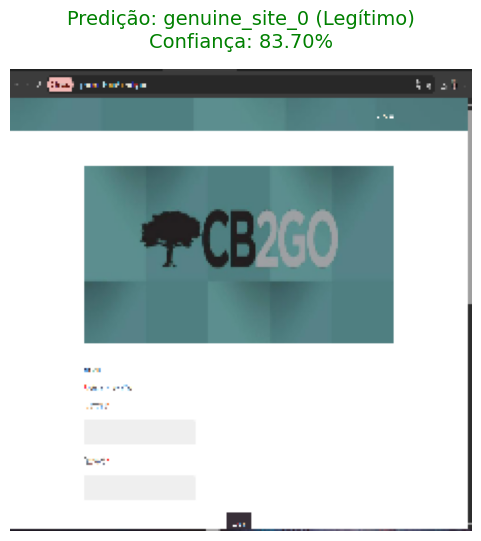

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

def testar_site_print(img_path, model):
    # 1. Carrega a imagem e redimensiona para 224x224 (exatamente o padrão do treino)
    img = image.load_img(img_path, target_size=(224, 224))

    # 2. Converte a imagem para um array numérico e normaliza os pixels (1./255)
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0

    # 3. Adiciona a dimensão do batch (o modelo espera receber uma lista de imagens)
    img_array = np.expand_dims(img_array, axis=0)

    # 4. Realiza a predição da probabilidade (Output Sigmoid)
    probabilidade = model.predict(img_array)[0][0]

    # 5. Define a classificação com base no limiar padrão de 0.5
    # IMPORTANTE: Confirme o mapeamento das classes no seu console,
    # se 'fraudulenta' for 0 e 'legitima' for 1, a lógica abaixo está correta.
    if probabilidade >= 0.5:
        resultado = "genuine_site_0 (Legítimo)"
        confianca = probabilidade * 100
        cor = "green"
    else:
        resultado = "fraudulenta (Phishing / Golpe)"
        confianca = (1 - probabilidade) * 100
        cor = "red"

    # 6. Exibe o resultado visual na tela
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Predição: {resultado}\nConfiança: {confianca:.2f}%", color=cor, fontsize=14, pad=15)
    plt.axis('off')
    plt.show()

# --- COMO USAR ---
# 1. Faça o upload do print para a raiz do Colab (clique no ícone de pasta na lateral esquerda e arraste a imagem)
# 2. Substitua o nome 'seu_print.png' abaixo pelo nome do arquivo que você upou
caminho_do_print = 'Screenshot_1.png'

# Executa o teste
testar_site_print(caminho_do_print, model)